<a href="https://colab.research.google.com/github/Diyah-futadya/UTS-PENAMBANGAN-DATA/blob/main/Training_Set_dan_Testing_Set_%26_Naive_Bayes_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

print("Library berhasil diimport")

Library berhasil diimport


In [3]:
data = pd.read_csv(
    'dataset_stunting_preprocessing.csv'
)

display(data.head())

print("Ukuran dataset:", data.shape)

,umur,jenis_kelamin,tinggi_badan,status
0,0,1,44.591973,stunted
1,0,1,56.705203,tinggi
2,0,1,46.863358,normal
3,0,1,47.508026,normal
4,0,1,42.743494,severely stunted


Ukuran dataset: (39425, 4)


In [4]:
X = data [
    ['umur', 'jenis_kelamin', 'tinggi_badan']
]

y = data['status']

print("Jumlah data prediktor:", X.shape)
print("Jumlah data target:", y.shape)

Jumlah data prediktor: (39425, 3)
Jumlah data target: (39425,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    train_size=0.8,
    random_state=42,
    stratify=y
)

print("Pembagian dataset berhasil!")

Pembagian dataset berhasil!


In [6]:
print("Jumlah data keseluruhan:", len(data))

print("Jumlah data Training:", len(X_train))
print("Jumlah data Testing:", len(X_test))

print("\nPersentase Training:",
      round(len(X_train)/len(data)*100, 2), "%")

print("Persentase testing:",
      round(len(X_test)/len(data)*100, 2), "%")

Jumlah data keseluruhan: 39425
Jumlah data Training: 31540
Jumlah data Testing: 7885

Persentase Training: 80.0 %
Persentase testing: 20.0 %


In [7]:
print("Distribusi status pada data training:")
print(y_train.value_counts())

print("\nDistribusi status pada data testing:")
print(y_test.value_counts())

Distribusi status pada data training:
status
normal              17211
tinggi               5579
severely stunted     5216
stunted              3534
Name: count, dtype: int64

Distribusi status pada data testing:
status
normal              4303
tinggi              1395
severely stunted    1304
stunted              883
Name: count, dtype: int64


In [9]:
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

print("Library berhasil diimport")

Library berhasil diimport


In [10]:
model_nb = GaussianNB()

print("Model Gaussian Naive Bayes berhasil dibuat")

Model Gaussian Naive Bayes berhasil dibuat


In [12]:
model_nb.fit(X_train, y_train)

print("Proses training berhasil!")

print("Jumlah data training:", len(X_train))

Proses training berhasil!
Jumlah data training: 31540


In [13]:
y_pred = model_nb.predict(X_test)

hasil_prediksi = pd.DataFrame({
    'Status_Aktual': y_test.values,
    'Status_Prediksi': y_pred
})

display(hasil_prediksi.head(10))

,Status_Aktual,Status_Prediksi
0,tinggi,severely stunted
1,normal,normal
2,severely stunted,normal
3,normal,normal
4,normal,normal
5,normal,normal
6,normal,normal
7,severely stunted,severely stunted
8,severely stunted,severely stunted
9,normal,normal


In [14]:
akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Model Naive Bayes:")
print(f"{akurasi * 100:.2f}%")

Akurasi Model Naive Bayes:
52.30%


In [15]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Classification Report:
                  precision    recall  f1-score   support

          normal       0.59      0.84      0.69      4303
severely stunted       0.29      0.38      0.33      1304
         stunted       0.00      0.00      0.00       883
          tinggi       0.00      0.00      0.00      1395

        accuracy                           0.52      7885
       macro avg       0.22      0.31      0.26      7885
    weighted avg       0.37      0.52      0.43      7885



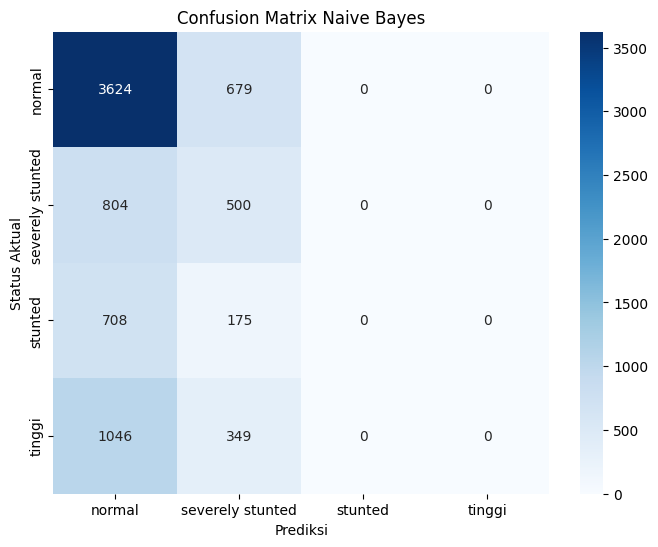

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model_nb.classes_,
    yticklabels=model_nb.classes_
)

plt.title('Confusion Matrix Naive Bayes')
plt.xlabel('Prediksi')
plt.ylabel('Status Aktual')
plt.show()

In [21]:
data_baru = pd.DataFrame(
    [[24, 1, 75]],
    columns=[
        'umur',
        'jenis_kelamin',
        'tinggi_badan'
    ]
)

prediksi = model_nb.predict(data_baru)

print("Hasil Prediksi Status Pertumbuhan:")
print(Prediksi[0])

Hasil Prediksi Status Pertumbuhan:
normal


In [22]:
import joblib

joblib.dump(
    model_nb,
    'model_naive_bayes_posyandu.pkl'
)

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [24]:
from google.colab import files

files.download('model_naive_bayes_posyandu.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>